In [1]:
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
customers = pd.read_csv(r"C:\Users\bonga\OneDrive\Desktop\revenue-leakage-analytic\data\cleaned\customers.csv")
discounts = pd.read_csv(r"C:\Users\bonga\OneDrive\Desktop\revenue-leakage-analytic\data\cleaned\discounts.csv")
order_items = pd.read_csv(r"C:\Users\bonga\OneDrive\Desktop\revenue-leakage-analytic\data\cleaned\order_items.csv")
orders = pd.read_csv(r"C:\Users\bonga\OneDrive\Desktop\revenue-leakage-analytic\data\cleaned\orders.csv")
payments = pd.read_csv(r"C:\Users\bonga\OneDrive\Desktop\revenue-leakage-analytic\data\cleaned\payments.csv")
products = pd.read_csv(r"C:\Users\bonga\OneDrive\Desktop\revenue-leakage-analytic\data\cleaned\products.csv")
regions = pd.read_csv(r"C:\Users\bonga\OneDrive\Desktop\revenue-leakage-analytic\data\cleaned\regions.csv")
returns = pd.read_csv(r"C:\Users\bonga\OneDrive\Desktop\revenue-leakage-analytic\data\cleaned\returns.csv")
shipping = pd.read_csv(r"C:\Users\bonga\OneDrive\Desktop\revenue-leakage-analytic\data\cleaned\shipping.csv")


In [3]:
datasets = {
    "customers": customers,
    "products": products,
    "orders": orders,
    "order_items": order_items,
    "payments": payments,
    "returns": returns,
    "shipping": shipping,
    "discounts": discounts,
    "regions": regions
}

In [4]:
for keys , values in datasets.items():
    print(values.columns)

Index(['customer_id', 'signup_date', 'region_id', 'customer_segment',
       'acquisition_channel', 'loyalty_tier', 'age_min', 'age_max'],
      dtype='object')
Index(['product_id', 'category', 'subcategory', 'brand', 'unit_cost',
       'list_price', 'supplier_id'],
      dtype='object')
Index(['order_id', 'customer_id', 'order_date', 'channel', 'order_status',
       'payment_method', 'gross_sales', 'net_sales', 'estimated_cost',
       'gross_profit', 'profit_margin_pct'],
      dtype='object')
Index(['order_id', 'product_id', 'quantity', 'unit_price', 'discount_pct',
       'net_sales', 'estimated_cost', 'gross_profit', 'profit_margin_pct',
       'gross_sales'],
      dtype='object')
Index(['order_id', 'order_date', 'payment_method', 'payment_id',
       'payment_status', 'transaction_amount'],
      dtype='object')
Index(['return_id', 'order_id', 'return_date', 'return_reason',
       'refund_amount'],
      dtype='object')
Index(['order_id', 'order_date', 'shipping_id', 'promise

In [5]:
datasets["customers"].columns

Index(['customer_id', 'signup_date', 'region_id', 'customer_segment',
       'acquisition_channel', 'loyalty_tier', 'age_min', 'age_max'],
      dtype='object')

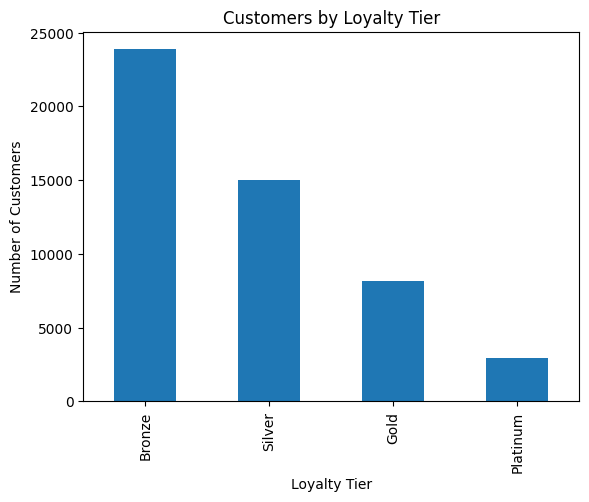

In [6]:
datasets["customers"]["loyalty_tier"].value_counts().plot(kind="bar")

plt.xlabel("Loyalty Tier")
plt.ylabel("Number of Customers")
plt.title("Customers by Loyalty Tier")
plt.show()

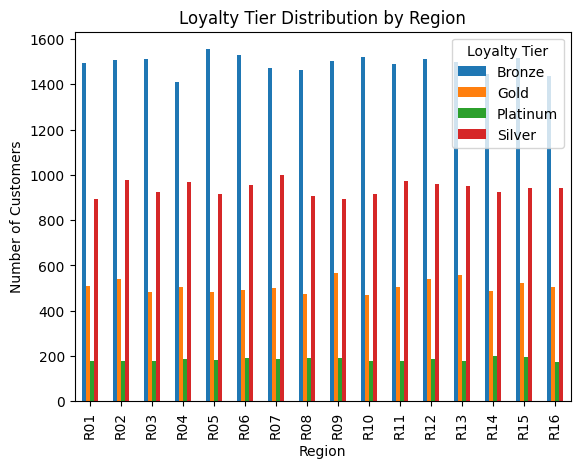

In [7]:
pd.crosstab(datasets["customers"]["region_id"],datasets["customers"]["loyalty_tier"]).plot(kind="bar")

plt.xlabel("Region")
plt.ylabel("Number of Customers")
plt.title("Loyalty Tier Distribution by Region")
plt.legend(title="Loyalty Tier")
plt.show()

In [8]:
total_revenue = datasets["orders"]["gross_sales"].sum()
net_revenue = datasets["orders"]["net_sales"].sum()
gross_profit = datasets["orders"]["gross_profit"].sum()

profit_margin = (gross_profit / net_revenue * 100)

total_orders = datasets["orders"]["order_id"].nunique()

aov = net_revenue / total_orders

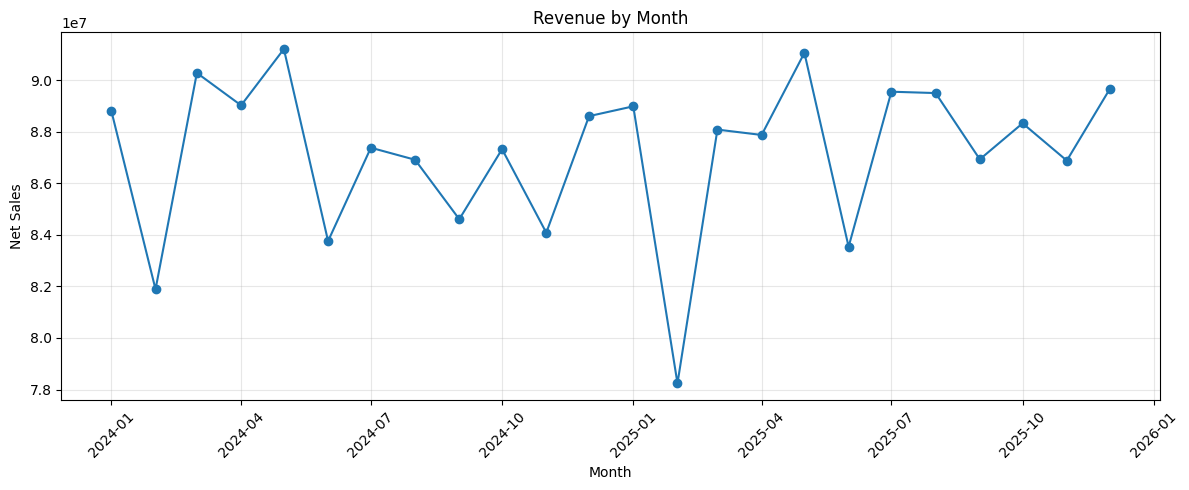

In [9]:


df = datasets["orders"].copy()

# Convert order_date to datetime
df["order_date"] = pd.to_datetime(df["order_date"])

# Aggregate revenue by month
monthly_revenue = (df.groupby(df["order_date"].dt.to_period("M"))["net_sales"].sum().reset_index())

# Convert period back to timestamp
monthly_revenue["order_date"] = monthly_revenue["order_date"].dt.to_timestamp()

plt.figure(figsize=(12, 5))

plt.plot(monthly_revenue["order_date"],monthly_revenue["net_sales"],marker="o")

plt.title("Revenue by Month")
plt.xlabel("Month")
plt.ylabel("Net Sales")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Analysis:
- Revenue shows significant month-to-month fluctuations.
- The highest revenue is observed around May 2024 and May 2025.
- The lowest revenue occurs around February 2025.
- Overall revenue remains relatively stable, mostly between ₹7.8 crore and ₹9.1 crore.
- There is no strong consistent upward or downward trend.
- The sharp fluctuations indicate seasonal or monthly changes in sales performance.

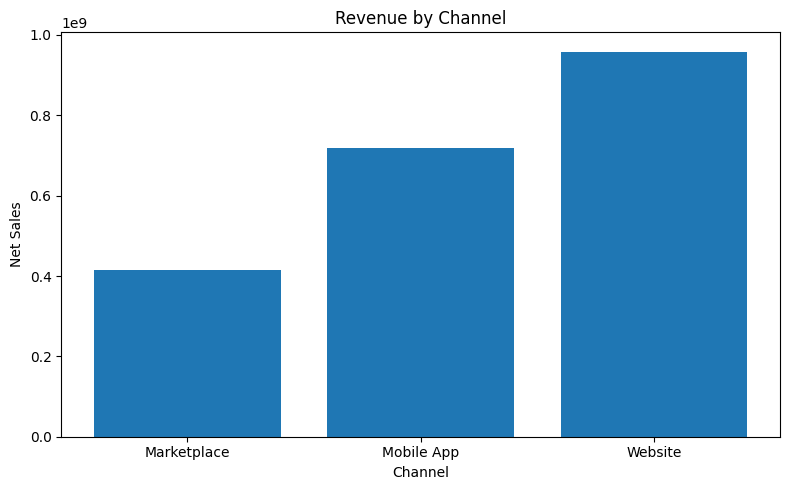

In [10]:
df = datasets["orders"].copy()


channel_revenue = (df.groupby("channel")["net_sales"].sum().reset_index())

plt.figure(figsize=(8, 5))

plt.bar(channel_revenue["channel"],channel_revenue["net_sales"])

plt.title("Revenue by Channel")
plt.xlabel("Channel")
plt.ylabel("Net Sales")

plt.tight_layout()
plt.show()

### Analysis:
- Revenue is compared across different sales channels.
- The channel with the highest revenue represents the strongest sales contributor.
- The lowest-performing channel may require further investigation.
- This visualization helps identify which channels generate the most revenue.
- Channel-level revenue can be used to support sales and marketing decisions.

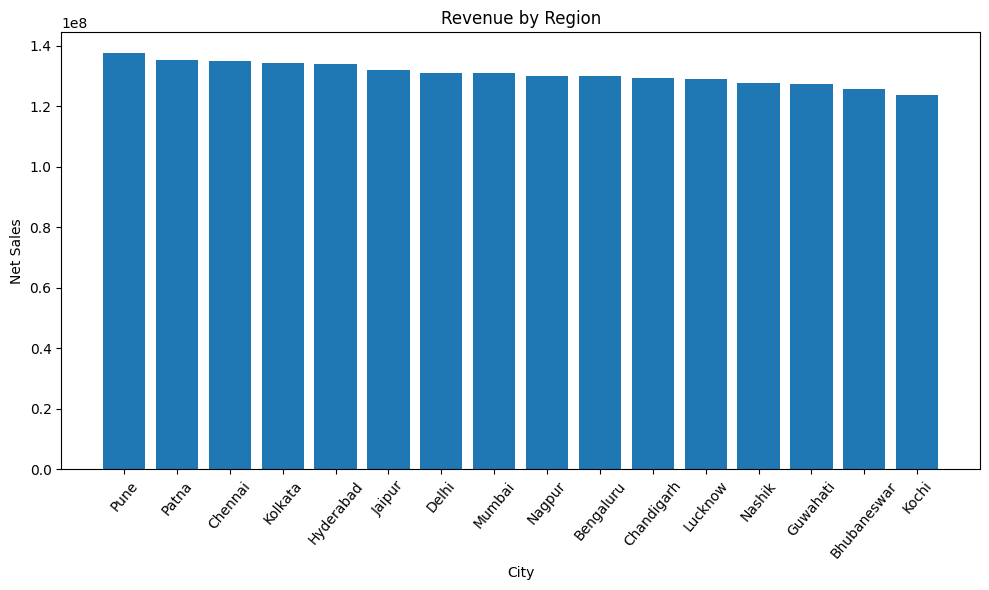

In [17]:
orders = datasets["orders"].copy()
customers = datasets["customers"].copy()
regions = datasets["regions"].copy()

orders_customers = orders.merge(customers[['customer_id','region_id']],on = 'customer_id',how = 'left')
order_regions = orders_customers.merge(regions[['region_id','city']],on = 'region_id',how = 'left')
region_revenue = order_regions.groupby('city')['net_sales'].sum().reset_index().sort_values('net_sales', ascending=False)

plt.figure(figsize=(10, 6))
plt.bar(region_revenue["city"],region_revenue["net_sales"])

plt.title("Revenue by Region")
plt.xlabel("City")
plt.ylabel("Net Sales")
plt.xticks(rotation=50)

plt.tight_layout()
plt.show()

### Analysis:
- Pune generates the highest revenue among the regions.
- Kochi and Bhubaneswar have relatively lower revenue compared with the other regions.
- Revenue is fairly evenly distributed across all cities, with no extreme regional difference.
- The difference between the highest and lowest revenue regions is relatively small.
- This indicates that the business has a broad and balanced geographical revenue distribution.

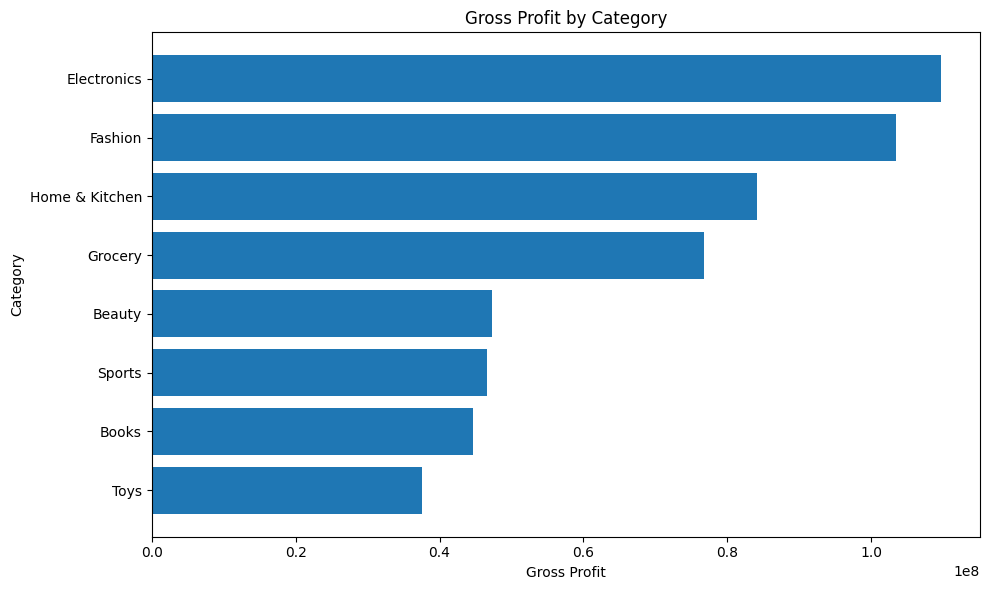

In [12]:
order_items = datasets["order_items"].copy()
products = datasets["products"].copy()

profit_data = order_items.merge(products[["product_id", "category", "unit_cost"]],on="product_id",how="left")
profit_data["gross_profit"] = (profit_data["quantity"] * (profit_data["unit_price"] - profit_data["unit_cost"]))
category_profit = (profit_data.groupby("category")["gross_profit"].sum().reset_index().sort_values("gross_profit", ascending=True))


plt.figure(figsize=(10, 6))
plt.barh(category_profit["category"],category_profit["gross_profit"])

plt.title("Gross Profit by Category")
plt.xlabel("Gross Profit")
plt.ylabel("Category")

plt.tight_layout()
plt.show()

### Analysis:
- Electronics generates the highest gross profit among all categories.
- Fashion is the second-highest profit-generating category.
- Home & Kitchen and Grocery also contribute significantly to total profit.
- Toys generates the lowest gross profit among the categories.
- There is a substantial gap between the highest-profit and lowest-profit categories.
- The business should focus on high-profit categories while investigating ways to improve the profitability of lower-performing categories.

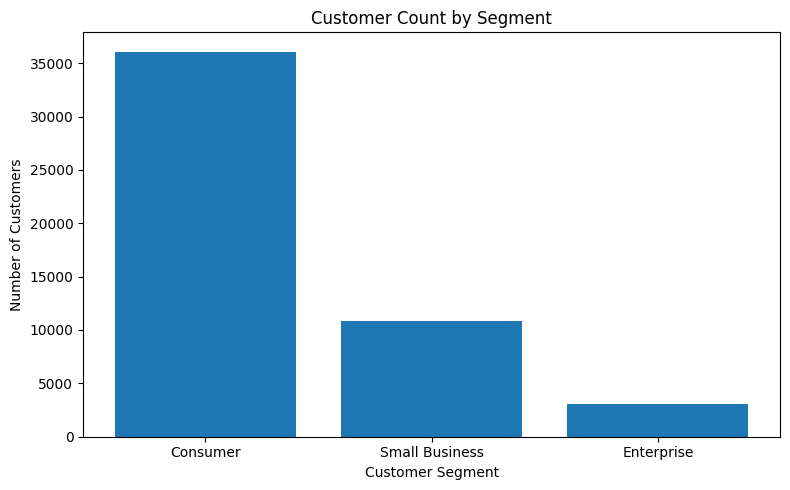

In [13]:
customers = datasets["customers"].copy()
orders = datasets["orders"].copy()
regions = datasets["regions"].copy()

segment_count = (customers.groupby("customer_segment")["customer_id"]
    .count()
    .reset_index(name="customer_count").sort_values("customer_count", ascending=False))

plt.figure(figsize=(8, 5))

plt.bar(segment_count["customer_segment"],segment_count["customer_count"])
plt.title("Customer Count by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

### Analysis:
- The Consumer segment has the largest customer base by a significant margin.
- Small Business has considerably fewer customers than Consumer.
- Enterprise has the smallest customer base among the three segments.
- The customer base is heavily concentrated in the Consumer segment.
- This distribution should be compared with revenue by segment to determine whether the largest customer segment is also the most valuable.

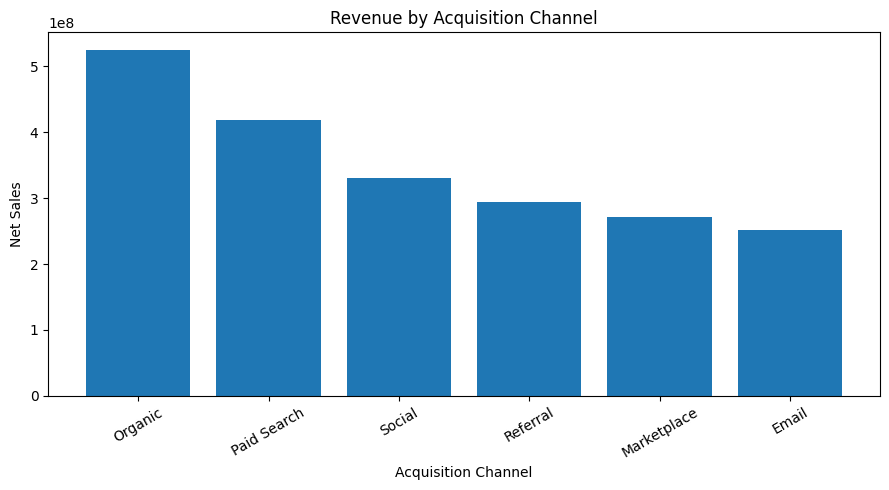

In [15]:
acquisition_revenue = (
    customer_orders.groupby("acquisition_channel")["net_sales"]
    .sum()
    .reset_index()
    .sort_values("net_sales", ascending=False)
)

plt.figure(figsize=(9, 5))

plt.bar(
    acquisition_revenue["acquisition_channel"],
    acquisition_revenue["net_sales"]
)

plt.title("Revenue by Acquisition Channel")
plt.xlabel("Acquisition Channel")
plt.ylabel("Net Sales")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

### Analysis:
- Organic is the highest revenue-generating acquisition channel.
- Paid Search is the second-highest contributor to revenue.
- Social generates moderate revenue, followed by Referral.
- Marketplace and Email contribute the lowest revenue among the channels.
- The results indicate that Organic and Paid Search are the strongest acquisition channels in terms of revenue generation.

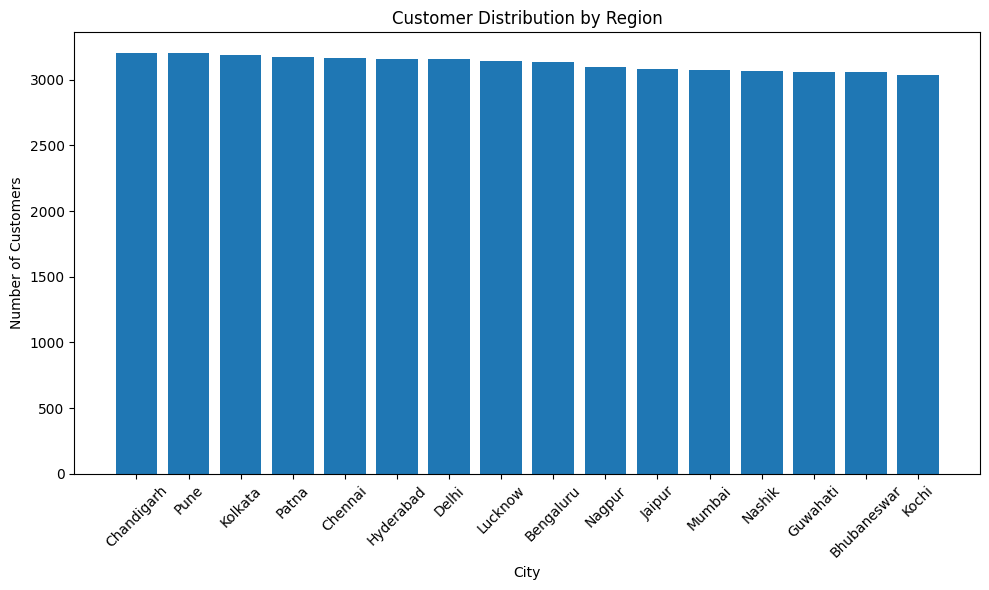

In [16]:
customer_regions = customers.merge(
    regions[["region_id", "city"]],
    on="region_id",
    how="left"
)
region_customers = (
    customer_regions.groupby("city")["customer_id"]
    .count()
    .reset_index(name="customer_count")
    .sort_values("customer_count", ascending=False)
)

plt.figure(figsize=(10, 6))

plt.bar(
    region_customers["city"],
    region_customers["customer_count"]
)

plt.title("Customer Distribution by Region")
plt.xlabel("City")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Analysis:
- Customer distribution is relatively balanced across all regions.
- Chandigarh has the highest number of customers, followed closely by Pune and Kolkata.
- Kochi has the lowest customer count among the regions.
- The difference between the highest and lowest regions is relatively small.
- This indicates that the customer base is geographically well distributed rather than concentrated in a few regions.

In [18]:
# Product Analytics

order_items = datasets["order_items"].copy()
products = datasets["products"].copy()

# Join order items with product information
product_data = order_items.merge(
    products[
        ["product_id", "category", "subcategory", "brand", "unit_cost"]
    ],
    on="product_id",
    how="left"
)

# Calculate revenue and gross profit
product_data["revenue"] = (
    product_data["quantity"] * product_data["unit_price"]
)

product_data["gross_profit"] = (
    product_data["quantity"] *
    (product_data["unit_price"] - product_data["unit_cost"])
)

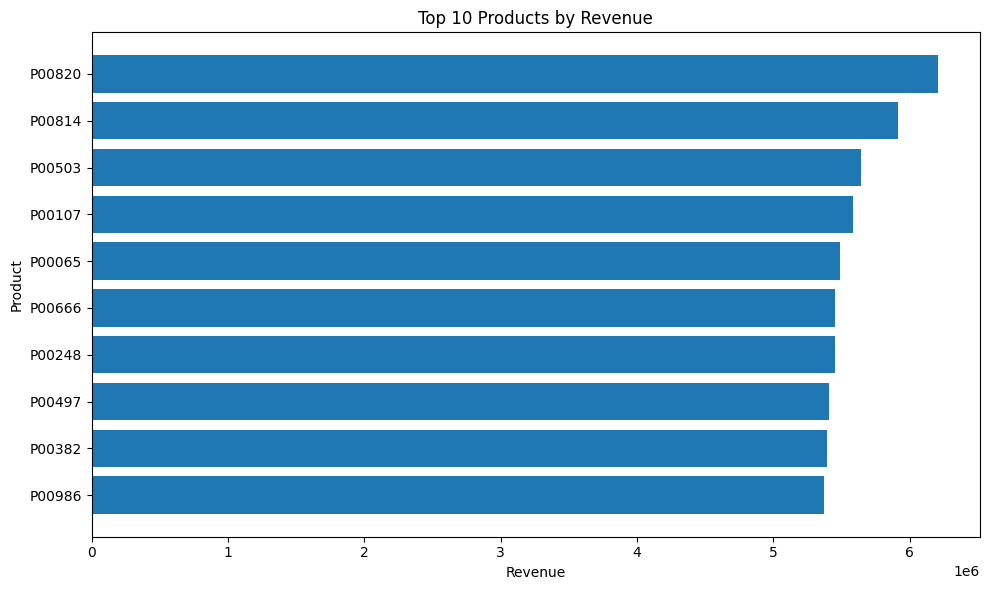

In [19]:
top_revenue = (
    product_data.groupby("product_id")["revenue"]
    .sum()
    .reset_index()
    .sort_values("revenue", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_revenue["product_id"].astype(str),
    top_revenue["revenue"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Analysis:
- Product P00820 generates the highest revenue among the top 10 products.
- P00814 and P00503 are the next strongest revenue-generating products.
- The top products have relatively similar revenue levels, except P00820 which leads the group.
- These products are major contributors to overall sales and should be monitored for demand and inventory.
- Revenue alone does not indicate profitability, so these products should also be compared using gross profit.

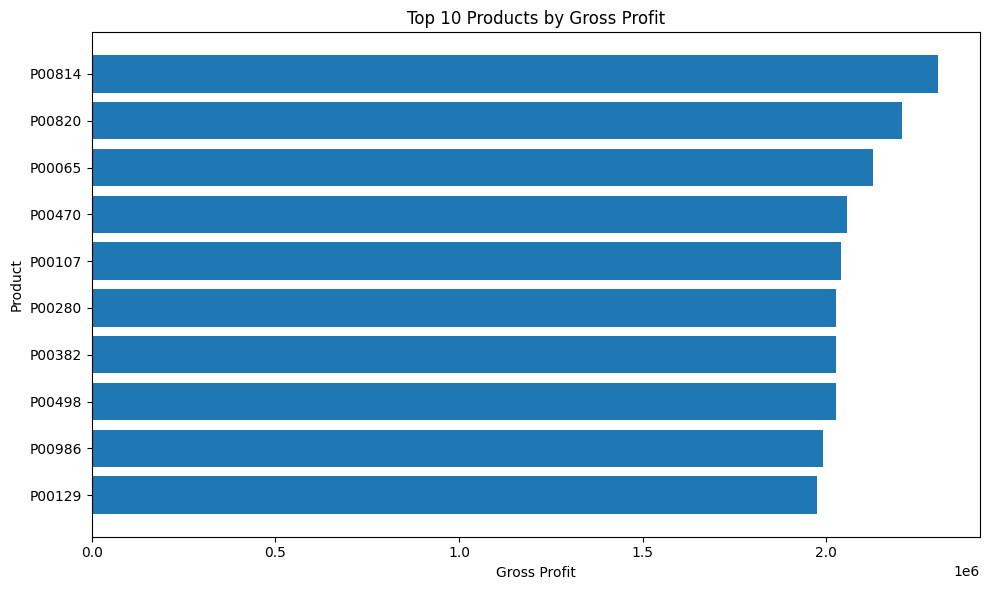

In [20]:
top_profit = (
    product_data.groupby("product_id")["gross_profit"]
    .sum()
    .reset_index()
    .sort_values("gross_profit", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_profit["product_id"].astype(str),
    top_profit["gross_profit"]
)

plt.title("Top 10 Products by Gross Profit")
plt.xlabel("Gross Profit")
plt.ylabel("Product")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

### Analysis:
- Product P00814 generates the highest gross profit among all products.
- P00820 is the second most profitable product and was also the highest revenue-generating product.
- P00065 ranks third in gross profit, showing strong profitability.
- Some products appear in both the Top 10 Revenue and Top 10 Profit lists, indicating strong overall performance.
- Revenue ranking and profit ranking are not identical, showing that higher sales do not always result in higher profit.
- High-profit products should be prioritized for inventory, pricing, and marketing decisions.

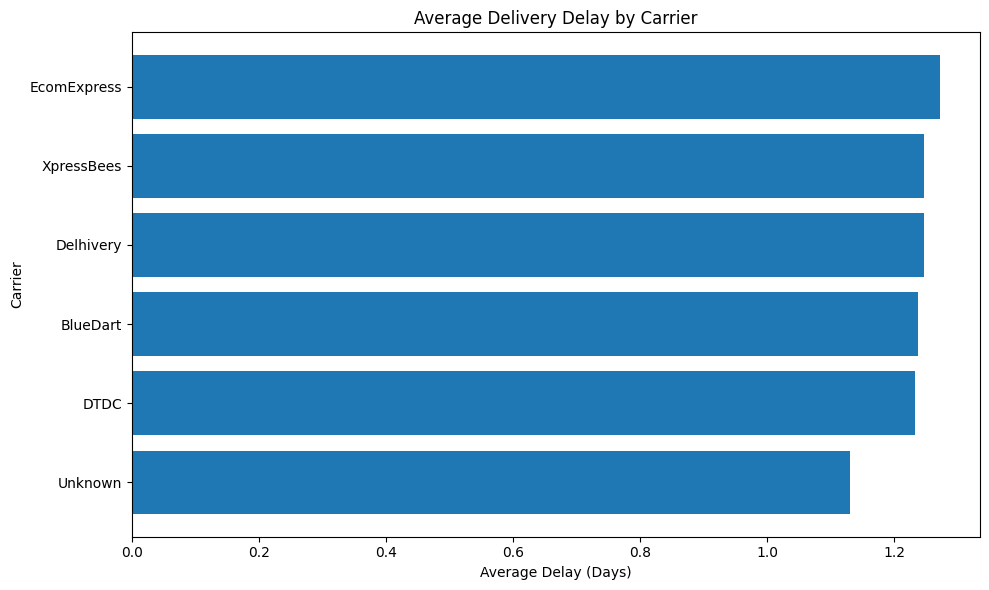

In [24]:
avg_delay = (
    shipping.groupby("carrier")["delivery_delay_days"]
    .mean()
    .reset_index()
    .sort_values("delivery_delay_days", ascending=True)
)

plt.figure(figsize=(10, 6))

plt.barh(
    avg_delay["carrier"],
    avg_delay["delivery_delay_days"]
)

plt.title("Average Delivery Delay by Carrier")
plt.xlabel("Average Delay (Days)")
plt.ylabel("Carrier")

plt.tight_layout()
plt.show()

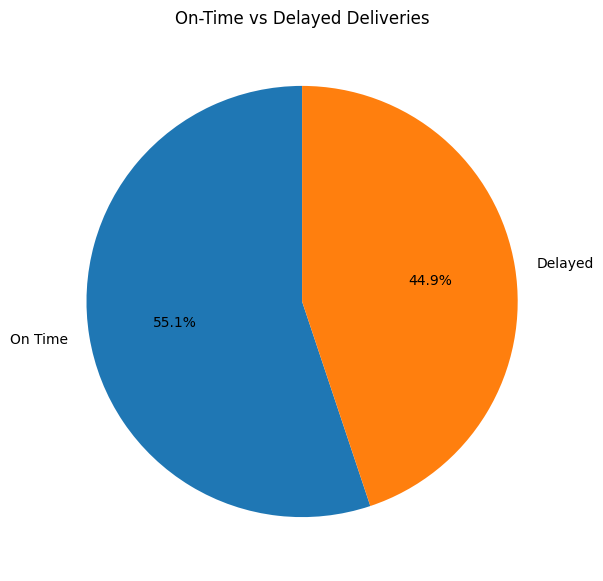

In [28]:
on_time = (shipping["delivery_delay_days"] <= 0).sum()
delayed = (shipping["delivery_delay_days"] > 0).sum()

status_counts = [on_time, delayed]
labels = ["On Time", "Delayed"]

plt.figure(figsize=(7, 7))

plt.pie(
    status_counts,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    
)

plt.title("On-Time vs Delayed Deliveries")

plt.show()

In [ ]:

.